In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("online_retail.csv", encoding="utf-8-sig")

df.columns = df.columns.str.strip().str.replace('ï»¿', '').str.replace('\ufeff', '')

print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])
print("Columns in dataset:", list(df.columns))
df.head()


Total rows: 541909
Total columns: 8
Columns in dataset: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom


In [2]:
print("Missing values in each column:")
print(df.isnull().sum())

df["InvoiceNo"] = df["InvoiceNo"].astype(str).str.strip()
df["StockCode"] = df["StockCode"].astype(str).str.strip()
df["Description"] = df["Description"].fillna("Unknown").astype(str).str.strip()
df["Country"] = df["Country"].astype(str).str.strip()

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df = df.dropna(subset=["InvoiceDate"])

df = df.drop_duplicates()

df["is_cancelled"] = df["InvoiceNo"].str.startswith("C") | (df["Quantity"] < 0)

print("\nTotal valid records:", len(df))
print("Cancellation records:", int(df["is_cancelled"].sum()))


Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Total valid records: 230656
Cancellation records: 4813


In [3]:
sales = df[(~df["is_cancelled"]) & (df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()

junk_codes = ["POST", "D", "M", "BANK CHARGES", "AMAZON FEE", "CRUK"]
sales = sales[~sales["StockCode"].isin(junk_codes)]

sales["TotalAmount"] = sales["Quantity"] * sales["UnitPrice"]

sales["is_guest"] = sales["CustomerID"].isna().astype(int)
sales["CustomerID"] = sales["CustomerID"].fillna(-1)

print("Cleaned sales records:", len(sales))
sales.head()


Cleaned sales records: 224823


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,is_cancelled,TotalAmount,is_guest
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-01-12 08:26:00,2.55,17850.0,United Kingdom,False,15.30,0
1,536365,71053,WHITE METAL LANTERN,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,False,20.34,0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-01-12 08:26:00,2.75,17850.0,United Kingdom,False,22.00,0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,False,20.34,0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,False,20.34,0


C:\Users\naman\AppData\Local\Temp\ipykernel_17308\976201112.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values, y=top_countries.index, palette="Blues_r")


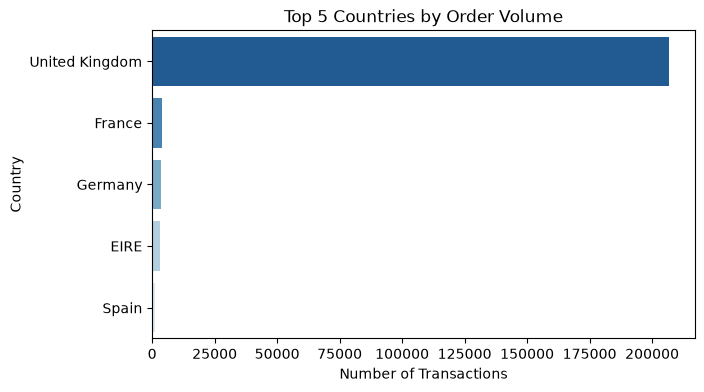

In [4]:

top_countries = sales["Country"].value_counts().head(5)

plt.figure(figsize=(7, 4))
sns.barplot(x=top_countries.values, y=top_countries.index, palette="Blues_r")
plt.title("Top 5 Countries by Order Volume")
plt.xlabel("Number of Transactions")
plt.ylabel("Country")
plt.show()


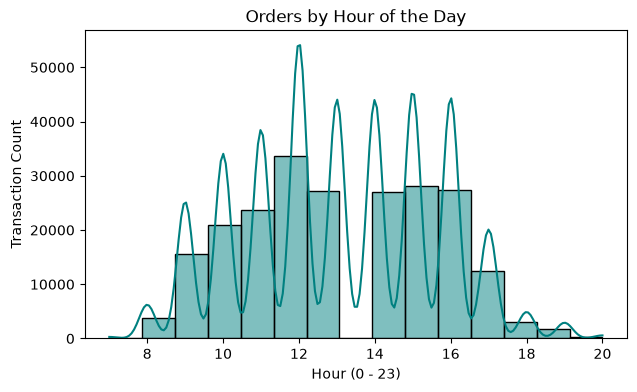

In [5]:

sales["Hour"] = sales["InvoiceDate"].dt.hour

plt.figure(figsize=(7, 4))
sns.histplot(sales["Hour"], bins=15, color="teal", kde=True)
plt.title("Orders by Hour of the Day")
plt.xlabel("Hour (0 - 23)")
plt.ylabel("Transaction Count")
plt.show()


In [6]:

print("Total Unique Orders:", sales["InvoiceNo"].nunique())
print("Total Unique Customers:", sales["CustomerID"].nunique())
print("Total Revenue:", round(sales["TotalAmount"].sum(), 2))
print("Average Item Price:", round(sales["UnitPrice"].mean(), 2))


Total Unique Orders: 8487
Total Unique Customers: 2990
Total Revenue: 4600813.17
Average Item Price: 3.8


In [7]:

orders = sales.groupby("InvoiceNo").agg(
    InvoiceDate=("InvoiceDate", "min"),
    CustomerID=("CustomerID", "first"),
    Country=("Country", "first"),
    is_guest=("is_guest", "first"),
    total_amount=("TotalAmount", "sum"),
    total_items=("Quantity", "sum")
).reset_index()

orders["average_price"] = (orders["total_amount"] / np.maximum(orders["total_items"], 1)).round(2)

orders["is_international"] = (orders["Country"] != "United Kingdom").astype(int)

orders["order_hour"] = orders["InvoiceDate"].dt.hour

orders.head()


,InvoiceNo,InvoiceDate,CustomerID,Country,is_guest,total_amount,total_items,average_price,is_international,order_hour
0,536365,2010-01-12 08:26:00,17850.0,United Kingdom,0,139.12,40,3.48,0,8
1,536366,2010-01-12 08:28:00,17850.0,United Kingdom,0,22.20,12,1.85,0,8
2,536367,2010-01-12 08:34:00,13047.0,United Kingdom,0,278.73,83,3.36,0,8
3,536368,2010-01-12 08:34:00,13047.0,United Kingdom,0,70.05,15,4.67,0,8
4,536369,2010-01-12 08:35:00,13047.0,United Kingdom,0,17.85,3,5.95,0,8


In [8]:
np.random.seed(42)

orders["risk_score"] = (
    0.30 * (orders["total_amount"] > 200) +
    0.25 * (orders["total_items"] > 30) +
    0.20 * orders["is_guest"] +
    0.15 * orders["is_international"] +
    0.10 * (orders["order_hour"] >= 20) +
    np.random.normal(0, 0.08, size=len(orders))
)

orders["risk_level"] = np.where(
    orders["risk_score"] > 0.45, 2,
    np.where(orders["risk_score"] > 0.15, 1, 0)
)

print("Target Class Counts:")
print(orders["risk_level"].value_counts())

print("\nTarget Class Percentage:")
print((orders["risk_level"].value_counts(normalize=True) * 100).round(2))


Target Class Counts:
risk_level
2    5099
1    2412
0     976
Name: count, dtype: int64

Target Class Percentage:
risk_level
2    60.08
1    28.42
0    11.50
Name: proportion, dtype: float64


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

features = [
    "total_amount",
    "total_items",
    "average_price",
    "is_guest",
    "is_international",
    "order_hour"
]

X = orders[features]
y = orders["risk_level"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 6789
Testing samples: 1698


In [10]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_model = LogisticRegression(max_iter=500, random_state=42)
lr_model.fit(X_train_scaled, y_train)
lr_pred = lr_model.predict(X_test_scaled)

print("Logistic Regression Train Accuracy:", round(accuracy_score(y_train, lr_model.predict(X_train_scaled)), 4))
print("Logistic Regression Test Accuracy:", round(accuracy_score(y_test, lr_pred), 4))
print("Logistic Regression Macro F1:", round(f1_score(y_test, lr_pred, average="macro"), 4))


Logistic Regression Train Accuracy: 0.6991
Logistic Regression Test Accuracy: 0.7008
Logistic Regression Macro F1: 0.5659


In [11]:
rf_model = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=5, random_state=42)
rf_model.fit(X_train, y_train)

train_acc = accuracy_score(y_train, rf_model.predict(X_train))
test_acc = accuracy_score(y_test, rf_model.predict(X_test))

print("Random Forest Train Accuracy:", round(train_acc, 4))
print("Random Forest Test Accuracy:", round(test_acc, 4))
print("Random Forest Macro F1:", round(f1_score(y_test, rf_model.predict(X_test), average="macro"), 4))


Random Forest Train Accuracy: 0.8978
Random Forest Test Accuracy: 0.9028
Random Forest Macro F1: 0.8712


     CLASSIFICATION REPORT (TEST SET)
                   precision    recall  f1-score   support

     Low Risk (0)       0.93      0.77      0.85       195
Moderate Risk (1)       0.87      0.77      0.82       483
    High Risk (2)       0.91      0.99      0.95      1020

         accuracy                           0.90      1698
        macro avg       0.90      0.85      0.87      1698
     weighted avg       0.90      0.90      0.90      1698



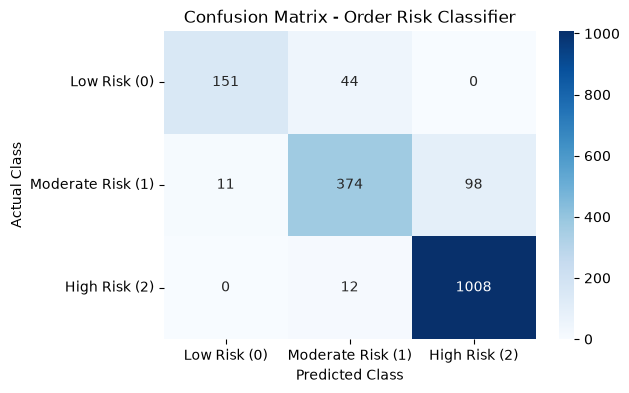

In [12]:
from sklearn.metrics import classification_report, confusion_matrix

target_names = ["Low Risk (0)", "Moderate Risk (1)", "High Risk (2)"]
rf_pred = rf_model.predict(X_test)

print("========================================")
print("     CLASSIFICATION REPORT (TEST SET)")
print("========================================")
print(classification_report(y_test, rf_pred, target_names=target_names))

cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=target_names, yticklabels=target_names)
plt.title("Confusion Matrix - Order Risk Classifier")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()


In [13]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [6, 8],
    "min_samples_leaf": [3, 5]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring="accuracy"
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print("Best Hyperparameters:", grid_search.best_params_)
print("Best Cross-Validation Score:", round(grid_search.best_score_, 4))
print("Tuned Test Accuracy:", round(accuracy_score(y_test, best_model.predict(X_test)), 4))


Best Hyperparameters: {'max_depth': 8, 'min_samples_leaf': 5, 'n_estimators': 50}
Best Cross-Validation Score: 0.8947
Tuned Test Accuracy: 0.9034


In [14]:
import joblib

joblib.dump(best_model, "order_risk_model.pkl")

joblib.dump(features, "features.pkl")

print("Model saved successfully as 'order_risk_model.pkl'")
print("Features saved successfully as 'features.pkl'")


Model saved successfully as 'order_risk_model.pkl'
Features saved successfully as 'features.pkl'


In [15]:
backend_code = """from fastapi import FastAPI
from pydantic import BaseModel
import joblib
import pandas as pd

# 1. Initialize FastAPI app
app = FastAPI(title="Order Risk Classification API")

# 2. Load trained model and features
model = joblib.load("order_risk_model.pkl")
features = joblib.load("features.pkl")

# 3. Define Request Body (Only 5 inputs required from the user!)
class Order(BaseModel):
    total_amount: float        # Total cart price in £
    total_items: int           # Total units in cart
    is_guest: int              # 1 if guest checkout, 0 if registered
    is_international: int      # 1 if shipping outside UK, 0 if domestic
    order_hour: int            # Hour of purchase (0 - 23)

# 4. Home endpoint
@app.get("/")
def home():
    return {"message": "Order Risk Classification API is running successfully!"}

# 5. Prediction endpoint
@app.post("/predict")
def predict_risk(order: Order):
    # Automatically calculate average_price internally (don't trouble the user!)
    calculated_avg_price = round(order.total_amount / max(order.total_items, 1), 2)
    
    # Assemble complete feature dictionary for the model
    order_features = {
        "total_amount": order.total_amount,
        "total_items": order.total_items,
        "average_price": calculated_avg_price,
        "is_guest": order.is_guest,
        "is_international": order.is_international,
        "order_hour": order.order_hour
    }
    
    input_df = pd.DataFrame([order_features])[features]
    pred_code = int(model.predict(input_df)[0])
    
    labels = {0: "Low Risk", 1: "Moderate Risk", 2: "High Risk"}
    actions = {
        0: "Auto-approve: Safe order for express dispatch.",
        1: "Standard Review: Verify order details before shipping.",
        2: "Hold Order: High cancellation risk, require customer confirmation."
    }
    
    return {
        "risk_code": pred_code,
        "risk_level": labels[pred_code],
        "recommended_action": actions[pred_code],
        "computed_average_price": calculated_avg_price
    }
"""

with open("backend.py", "w", encoding="utf-8") as f:
    f.write(backend_code)

print("backend.py generated successfully!")
print("To run the API, execute in your terminal:")
print("uvicorn backend:app --reload --port 8000")


backend.py generated successfully!
To run the API, execute in your terminal:
uvicorn backend:app --reload --port 8000


In [16]:
user_input = {
    "total_amount": 320.0,
    "total_items": 45,
    "is_guest": 1,
    "is_international": 1,
    "order_hour": 22
}

user_input["average_price"] = round(user_input["total_amount"] / max(user_input["total_items"], 1), 2)

sample_df = pd.DataFrame([user_input])[features]
pred = best_model.predict(sample_df)[0]
labels = {0: "Low Risk", 1: "Moderate Risk", 2: "High Risk"}

print("Test Order Predicted:", labels[pred])


Test Order Predicted: High Risk
